# CP Decomposition Benchmark — Same-Tensor Protocol

**Purpose.** This notebook implements the deterministic tensor-generation pipeline for benchmarking CP decomposition methods. Every method sees the *identical* tensor for each (rank, sparsity, SNR) cell, replicated across `N` Monte Carlo seeds.

**This notebook covers:**
1. Environment setup and seeding utilities
2. Synthetic CP tensor generation with controlled sparsity and noise
3. Persisting tensors to disk in both `.npy` and `.mat` formats
4. Loading + running **CP-ALS** as the baseline method
5. Evaluation metrics: factor recovery error (with permutation/sign alignment), reconstruction error, runtime
6. A single-cell smoke test, then a small grid sweep

Other methods (MPALS, TensorNOODL, K-TSVD, TT-DL, Tucker-DL) plug into the same `run_method(tensor_path, ...)` interface defined below. Each method gets its own notebook or module that loads from disk and writes to the shared results log.

## 1. Setup

In [1]:
# Core scientific stack
import numpy as np
import scipy.io as sio
from scipy.optimize import linear_sum_assignment

# Tensor library (tensorly is the standard for CP/Tucker in Python)
import tensorly as tl
from tensorly.decomposition import parafac, CP
from tensorly.cp_tensor import cp_to_tensor, cp_normalize

# Utilities
import os
import time
import json
import hashlib
from pathlib import Path
from dataclasses import dataclass, asdict
from typing import Optional

import pandas as pd
import matplotlib.pyplot as plt

tl.set_backend('numpy')

# Project layout
ROOT = Path('./benchmark_data')
TENSOR_DIR = ROOT / 'tensors'
RESULTS_DIR = ROOT / 'results'
TENSOR_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print(f'tensorly version: {tl.__version__}')
print(f'numpy version:    {np.__version__}')
print(f'tensor dir:       {TENSOR_DIR.resolve()}')
print(f'results dir:      {RESULTS_DIR.resolve()}')

tensorly version: 0.9.0
numpy version:    2.4.4
tensor dir:       /home/claude/work/benchmark_data/tensors
results dir:      /home/claude/work/benchmark_data/results


## 2. Tensor Generation

We build a 3-way tensor $\mathcal{T} \in \mathbb{R}^{I \times J \times K}$ from sparse factor matrices via the CP model:

$$\mathcal{T} = \sum_{r=1}^{R} \lambda_r \, \mathbf{a}_r \circ \mathbf{b}_r \circ \mathbf{c}_r + \mathcal{E}$$

**Design choices following the TensorNOODL setup:**
- Factor entries drawn i.i.d. Gaussian, then a fraction `(1 - sparsity)` zeroed out per column.
- Each column $\ell_2$-normalized so $\lambda_r$ carries the magnitude.
- Additive Gaussian noise calibrated to a target SNR (dB).
- **Deterministic:** identical (seed, params) → bitwise-identical tensor.

In [2]:
@dataclass(frozen=True)
class TensorSpec:
    """Fully specifies a synthetic tensor. Hashable -> deterministic filenames."""
    dims: tuple        # e.g. (50, 50, 50)
    rank: int          # true CP rank
    sparsity: float    # fraction of NONZERO entries per factor column (e.g. 0.05 = 5% nonzero)
    snr_db: float      # signal-to-noise ratio in decibels; use np.inf for noiseless
    seed: int          # RNG seed

    def cell_id(self) -> str:
        """Stable, human-readable id used as the filename stem."""
        dims_str = 'x'.join(str(d) for d in self.dims)
        snr_str = 'inf' if np.isinf(self.snr_db) else f'{self.snr_db:g}'
        return f'd{dims_str}_r{self.rank}_s{self.sparsity:g}_snr{snr_str}_seed{self.seed}'

    def hash(self) -> str:
        return hashlib.sha256(self.cell_id().encode()).hexdigest()[:12]


def generate_sparse_factor(n_rows: int, rank: int, sparsity: float, rng: np.random.Generator) -> np.ndarray:
    """Generate an (n_rows x rank) factor matrix with column sparsity.

    Each column has approximately `sparsity * n_rows` nonzero entries
    (Gaussian), with the column then unit-normalized.
    """
    F = rng.standard_normal(size=(n_rows, rank))
    n_keep = max(1, int(round(sparsity * n_rows)))
    for r in range(rank):
        # Keep the n_keep largest-magnitude entries, zero the rest
        idx = np.argpartition(-np.abs(F[:, r]), n_keep - 1)[:n_keep]
        mask = np.zeros(n_rows, dtype=bool)
        mask[idx] = True
        F[~mask, r] = 0.0
        # Unit-normalize the column (after zeroing)
        norm = np.linalg.norm(F[:, r])
        if norm > 0:
            F[:, r] /= norm
    return F


def generate_cp_tensor(spec: TensorSpec):
    """Build T = sum_r lambda_r * a_r o b_r o c_r + noise.

    Returns: (tensor, ground_truth) where ground_truth is a dict with
    keys 'factors' (list of arrays), 'weights' (1D array), and 'spec'.
    """
    rng = np.random.default_rng(spec.seed)

    factors = [generate_sparse_factor(d, spec.rank, spec.sparsity, rng) for d in spec.dims]
    weights = np.ones(spec.rank)  # magnitudes absorbed into columns at gen time; could randomize

    clean = cp_to_tensor((weights, factors))

    if np.isinf(spec.snr_db):
        noisy = clean
    else:
        signal_power = np.mean(clean ** 2)
        noise_power = signal_power / (10 ** (spec.snr_db / 10.0))
        noise = rng.standard_normal(size=clean.shape) * np.sqrt(noise_power)
        noisy = clean + noise

    truth = {'factors': factors, 'weights': weights, 'spec': spec, 'clean': clean}
    return noisy, truth


# Quick sanity check
_spec = TensorSpec(dims=(20, 20, 20), rank=5, sparsity=0.2, snr_db=20.0, seed=42)
_T, _truth = generate_cp_tensor(_spec)
print(f'cell_id:        {_spec.cell_id()}')
print(f'tensor shape:   {_T.shape}')
print(f'tensor dtype:   {_T.dtype}')
print(f'factor 0 shape: {_truth["factors"][0].shape}')
print(f'factor 0 nnz per col: {(_truth["factors"][0] != 0).sum(axis=0)}')
print(f'clean ||.||_F:  {np.linalg.norm(_truth["clean"]):.4f}')
print(f'noise ||.||_F:  {np.linalg.norm(_T - _truth["clean"]):.4f}')

cell_id:        d20x20x20_r5_s0.2_snr20_seed42
tensor shape:   (20, 20, 20)
tensor dtype:   float64
factor 0 shape: (20, 5)
factor 0 nnz per col: [4 4 4 4 4]
clean ||.||_F:  2.2203
noise ||.||_F:  0.2228


## 3. Persist Tensors to Disk

Saving in both formats so MATLAB-based implementations (K-TSVD, original TT-DL) can read them too. Ground truth lives in a sidecar `.npz` so methods can't "see" it during decomposition.

In [3]:
def save_tensor(tensor: np.ndarray, truth: dict, out_dir: Path = TENSOR_DIR) -> dict:
    """Save tensor (.npy + .mat) and ground truth (.npz) to disk.

    Returns a dict of paths.
    """
    spec: TensorSpec = truth['spec']
    stem = spec.cell_id()

    npy_path = out_dir / f'{stem}.npy'
    mat_path = out_dir / f'{stem}.mat'
    truth_path = out_dir / f'{stem}_truth.npz'
    meta_path = out_dir / f'{stem}_meta.json'

    np.save(npy_path, tensor)
    sio.savemat(mat_path, {'T': tensor})
    np.savez(
        truth_path,
        **{f'factor_{i}': F for i, F in enumerate(truth['factors'])},
        weights=truth['weights'],
        clean=truth['clean'],
    )
    with open(meta_path, 'w') as f:
        meta = asdict(spec)
        meta['dims'] = list(meta['dims'])  # JSON can't serialize tuples
        meta['snr_db'] = 'inf' if np.isinf(spec.snr_db) else spec.snr_db
        json.dump(meta, f, indent=2)

    return {
        'tensor_npy': npy_path,
        'tensor_mat': mat_path,
        'truth_npz': truth_path,
        'meta_json': meta_path,
    }


def load_tensor(stem: str, in_dir: Path = TENSOR_DIR):
    """Methods call this. They get the tensor + spec, NOT the ground truth."""
    T = np.load(in_dir / f'{stem}.npy')
    with open(in_dir / f'{stem}_meta.json') as f:
        meta = json.load(f)
    return T, meta


def load_truth(stem: str, in_dir: Path = TENSOR_DIR):
    """Only the evaluator calls this — after the method has finished."""
    data = np.load(in_dir / f'{stem}_truth.npz')
    n_factors = sum(1 for k in data.files if k.startswith('factor_'))
    factors = [data[f'factor_{i}'] for i in range(n_factors)]
    return {'factors': factors, 'weights': data['weights'], 'clean': data['clean']}


# Save the sanity-check tensor
paths = save_tensor(_T, _truth)
for k, v in paths.items():
    print(f'{k:14s}: {v}  ({v.stat().st_size / 1024:.1f} KB)')

tensor_npy    : benchmark_data/tensors/d20x20x20_r5_s0.2_snr20_seed42.npy  (62.6 KB)
tensor_mat    : benchmark_data/tensors/d20x20x20_r5_s0.2_snr20_seed42.mat  (62.7 KB)
truth_npz     : benchmark_data/tensors/d20x20x20_r5_s0.2_snr20_seed42_truth.npz  (66.1 KB)
meta_json     : benchmark_data/tensors/d20x20x20_r5_s0.2_snr20_seed42_meta.json  (0.1 KB)


## 4. Evaluation Metrics

CP factors are only identifiable up to (a) column permutation and (b) per-column sign. Any honest factor-recovery metric must align the recovered factors to ground truth before comparing.

We use the Hungarian algorithm on a cosine-similarity cost matrix to find the optimal column permutation across all modes simultaneously.

In [4]:
def align_factors(true_factors, est_factors):
    """Align estimated CP factors to true factors via Hungarian assignment.

    Returns (aligned_est_factors, perm, signs). Cost matrix uses the
    product of per-mode cosine similarities — this is the standard way
    to handle the permutation ambiguity in CP.
    """
    R = true_factors[0].shape[1]
    R_est = est_factors[0].shape[1]
    assert R == R_est, f'rank mismatch: true={R}, est={R_est}'

    # Normalize columns for cosine similarity
    def _norm_cols(F):
        n = np.linalg.norm(F, axis=0, keepdims=True)
        n = np.where(n == 0, 1.0, n)
        return F / n

    true_n = [_norm_cols(F) for F in true_factors]
    est_n = [_norm_cols(F) for F in est_factors]

    # cost[i, j] = -prod_m |<true[m][:, i], est[m][:, j]>|
    # (absolute value handles sign ambiguity; negation turns max-sim into min-cost)
    cost = np.ones((R, R))
    for true_F, est_F in zip(true_n, est_n):
        sim = np.abs(true_F.T @ est_F)
        cost *= sim
    cost = -cost

    row_ind, col_ind = linear_sum_assignment(cost)
    # col_ind[i] is the estimated column that matches true column row_ind[i]
    perm = np.empty(R, dtype=int)
    perm[row_ind] = col_ind

    aligned = [F[:, perm].copy() for F in est_factors]

    # Sign-flip each column to match sign of dominant inner product on mode 0
    signs = np.sign(np.sum(true_n[0] * _norm_cols(aligned[0]), axis=0))
    signs = np.where(signs == 0, 1.0, signs)
    # Apply sign to one factor per column (mode 0); other modes are unaffected
    # since CP sign ambiguity requires sign products to be +1 per column.
    # To be safe, flip the first mode only:
    aligned[0] = aligned[0] * signs

    return aligned, perm, signs


def factor_error(true_factors, est_factors) -> float:
    """Average relative Frobenius error across modes, after alignment."""
    aligned, _, _ = align_factors(true_factors, est_factors)
    errs = []
    for T, E in zip(true_factors, aligned):
        # Per-column unit-normalize both, since CP factors only identifiable up to per-column scaling
        def _n(F):
            n = np.linalg.norm(F, axis=0, keepdims=True)
            n = np.where(n == 0, 1.0, n)
            return F / n
        Tn, En = _n(T), _n(E)
        errs.append(np.linalg.norm(Tn - En) / max(np.linalg.norm(Tn), 1e-12))
    return float(np.mean(errs))


def reconstruction_error(clean_tensor, est_weights, est_factors) -> float:
    """Relative Frobenius error of the reconstructed CP tensor vs. clean ground truth."""
    T_hat = cp_to_tensor((est_weights, est_factors))
    return float(np.linalg.norm(clean_tensor - T_hat) / max(np.linalg.norm(clean_tensor), 1e-12))


def evaluate(stem: str, est_weights, est_factors, runtime_s: float, method_name: str, extra: Optional[dict] = None) -> dict:
    """Compute all metrics for one (tensor, method) run and return a flat record."""
    truth = load_truth(stem)
    with open(TENSOR_DIR / f'{stem}_meta.json') as f:
        meta = json.load(f)
    rec = {
        'cell_id': stem,
        'method': method_name,
        'rank_true': len(truth['weights']),
        'rank_est': len(est_weights),
        'sparsity': meta['sparsity'],
        'snr_db': meta['snr_db'],
        'seed': meta['seed'],
        'dims': 'x'.join(str(d) for d in meta['dims']),
        'factor_err': factor_error(truth['factors'], est_factors),
        'recon_err': reconstruction_error(truth['clean'], est_weights, est_factors),
        'runtime_s': runtime_s,
    }
    if extra:
        rec.update(extra)
    return rec

## 5. Baseline Method — CP-ALS

This is the canonical CP decomposition algorithm (Alternating Least Squares). It's the floor every other method must beat. The wrapper signature here — `(tensor_path, rank, **kwargs) -> (weights, factors, runtime, extras)` — is what every other method module should implement, so they're all swappable.

In [5]:
def run_cp_als(stem: str, rank: int, n_iter_max: int = 500, tol: float = 1e-7, init_seed: int = 0):
    """Run CP-ALS on the tensor identified by `stem`. Returns (weights, factors, runtime_s, extras)."""
    T, _ = load_tensor(stem)

    t0 = time.perf_counter()
    # tensorly's parafac uses ALS by default
    cp_tensor = parafac(
        tl.tensor(T),
        rank=rank,
        n_iter_max=n_iter_max,
        tol=tol,
        init='random',
        random_state=init_seed,
        normalize_factors=True,
    )
    runtime = time.perf_counter() - t0

    weights, factors = cp_tensor
    extras = {'n_iter_max': n_iter_max, 'tol': tol, 'init_seed': init_seed}
    return np.asarray(weights), [np.asarray(F) for F in factors], runtime, extras


# Smoke test: run on the sanity-check tensor
_stem = _spec.cell_id()
w, F, rt, extras = run_cp_als(_stem, rank=_spec.rank, n_iter_max=300, init_seed=0)
record = evaluate(_stem, w, F, rt, method_name='CP-ALS', extra=extras)
for k, v in record.items():
    print(f'{k:14s}: {v}')

cell_id       : d20x20x20_r5_s0.2_snr20_seed42
method        : CP-ALS
rank_true     : 5
rank_est      : 5
sparsity      : 0.2
snr_db        : 20.0
seed          : 42
dims          : 20x20x20
factor_err    : 0.30551561689012624
recon_err     : 0.02014998763954691
runtime_s     : 0.01636972900001865
n_iter_max    : 300
tol           : 1e-07
init_seed     : 0


## 6. Results Log

All method runs append to a single CSV. This becomes the source of truth for plots and tables in the paper.

In [6]:
RESULTS_CSV = RESULTS_DIR / 'runs.csv'

def log_result(record: dict, csv_path: Path = RESULTS_CSV):
    """Append one result record to the CSV. Writes header on first call."""
    df = pd.DataFrame([record])
    if csv_path.exists():
        df.to_csv(csv_path, mode='a', header=False, index=False)
    else:
        df.to_csv(csv_path, index=False)

log_result(record)
print(f'Logged to {RESULTS_CSV}')
print(pd.read_csv(RESULTS_CSV))

Logged to benchmark_data/results/runs.csv
                          cell_id  method  rank_true  rank_est  sparsity  \
0  d20x20x20_r5_s0.2_snr20_seed42  CP-ALS          5         5       0.2   

   snr_db  seed      dims  factor_err  recon_err  runtime_s  n_iter_max  \
0    20.0    42  20x20x20    0.305516    0.02015    0.01637         300   

            tol  init_seed  
0  1.000000e-07          0  


## 7. Small Grid Sweep (Smoke Test for the Full Pipeline)

A miniature version of what the full benchmark will look like: a handful of seeds × a couple of cells. This is the loop you'll scale up to the full grid (e.g. `seeds = [42, 26, 91, 7, 13, 100, 256, 314, 512, 1024]` from your methodology note).

In [7]:
# Mini-grid: 2 SNRs x 2 ranks x 3 seeds = 12 tensors, all run with CP-ALS
SEEDS = [42, 26, 91]
RANKS = [5, 10]
SNRS = [20.0, 10.0]
DIMS = (30, 30, 30)
SPARSITY = 0.2

specs = [
    TensorSpec(dims=DIMS, rank=r, sparsity=SPARSITY, snr_db=snr, seed=s)
    for s in SEEDS for r in RANKS for snr in SNRS
]

# Step 1: generate + save every tensor (deterministic; safe to re-run)
for spec in specs:
    if (TENSOR_DIR / f'{spec.cell_id()}.npy').exists():
        continue
    T, truth = generate_cp_tensor(spec)
    save_tensor(T, truth)

print(f'Generated {len(specs)} tensors.')

# Step 2: run CP-ALS on each, log results
for spec in specs:
    stem = spec.cell_id()
    w, F, rt, extras = run_cp_als(stem, rank=spec.rank, n_iter_max=300, init_seed=0)
    rec = evaluate(stem, w, F, rt, method_name='CP-ALS', extra=extras)
    log_result(rec)

print('Done. Tail of results:')
df = pd.read_csv(RESULTS_CSV)
print(df.tail(len(specs)).to_string(index=False))

Generated 12 tensors.


Done. Tail of results:
                        cell_id method  rank_true  rank_est  sparsity  snr_db  seed     dims  factor_err  recon_err  runtime_s  n_iter_max          tol  init_seed
 d30x30x30_r5_s0.2_snr20_seed42 CP-ALS          5         5       0.2    20.0    42 30x30x30    0.896828   0.012242   0.016942         300 1.000000e-07          0
 d30x30x30_r5_s0.2_snr10_seed42 CP-ALS          5         5       0.2    10.0    42 30x30x30    0.531945   0.038722   0.032558         300 1.000000e-07          0
d30x30x30_r10_s0.2_snr20_seed42 CP-ALS         10        10       0.2    20.0    42 30x30x30    0.941734   0.018447   0.085021         300 1.000000e-07          0
d30x30x30_r10_s0.2_snr10_seed42 CP-ALS         10        10       0.2    10.0    42 30x30x30    0.999488   0.058329   0.012551         300 1.000000e-07          0
 d30x30x30_r5_s0.2_snr20_seed26 CP-ALS          5         5       0.2    20.0    26 30x30x30    0.940534   0.012912   0.014885         300 1.000000e-07          0

## 8. Quick Summary Plot

Mean ± std factor-recovery error across seeds, broken out by rank and SNR. This is the basic plot shape every method comparison will use.

   rank_true  snr_db  factor_err_mean  factor_err_std  n
0          5    10.0         0.852112        0.285076  3
1          5    20.0         0.802732        0.339343  4
2         10    10.0         0.972108        0.162838  3
3         10    20.0         1.006735        0.153566  3


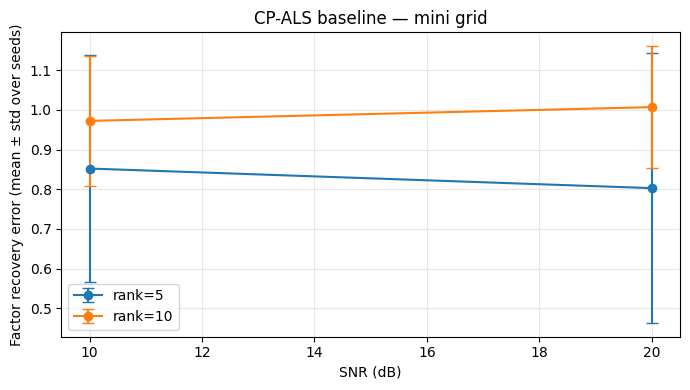

In [8]:
df = pd.read_csv(RESULTS_CSV)
df_cpals = df[df['method'] == 'CP-ALS']

agg = (
    df_cpals
    .groupby(['rank_true', 'snr_db'])
    .agg(factor_err_mean=('factor_err', 'mean'),
         factor_err_std=('factor_err', 'std'),
         n=('factor_err', 'size'))
    .reset_index()
)
print(agg)

fig, ax = plt.subplots(figsize=(7, 4))
for rank in sorted(agg['rank_true'].unique()):
    sub = agg[agg['rank_true'] == rank].sort_values('snr_db')
    ax.errorbar(sub['snr_db'], sub['factor_err_mean'], yerr=sub['factor_err_std'],
                marker='o', capsize=4, label=f'rank={rank}')
ax.set_xlabel('SNR (dB)')
ax.set_ylabel('Factor recovery error (mean ± std over seeds)')
ax.set_title('CP-ALS baseline — mini grid')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Next Steps

1. **Add the other five methods** as sibling modules, each exposing `run_<method>(stem, rank, **kwargs) -> (weights, factors, runtime, extras)`. They all call `load_tensor(stem)` — never `generate_cp_tensor` — so the same-tensor guarantee holds.
2. **Scale the grid.** Move `SEEDS`, `RANKS`, `SNRS`, sparsity levels, and dims into a config block at the top. The TensorNOODL paper used 3 seeds; you proposed 10. Either is reasonable; the loop above doesn't change.
3. **Initialization-sensitivity sub-experiment.** Re-run with `init_seed` varying for fixed tensor seed. This isolates algorithmic stability from data variance — the two source papers both flagged this as worth a dedicated section.
4. **Real-data section.** Drop in Urban HSI (or whichever real tensors you have) by writing a `load_real_tensor(name)` that bypasses generation and points at fixed files. The `run_<method>` interface stays identical.
5. **Reproducibility audit.** Re-run the whole notebook end-to-end on a clean machine; the CSV should be bitwise-identical to a reference copy. If not, somewhere a seed leaked.